# Projet : Prédiction de la souscription d'un client à un dépôt bancaire

### 1. Introduction

L'objectif de ce projet est de construire un modèle de Machine Learning capable de prédire si un client va souscrire à un dépôt bancaire

### 2. Préparation des données

Cette étape consiste à explorer le dataset, traiter les valeurs manquantes et encoder les variables catégorielles.

**Bibliothèques utilisées :**
- Pandas
- NumPy
- Matplotlib
- Scikit-learn

Tout d'abord, on importe les bibliotheques necessaires et on charge notre jeu de donnees:

In [21]:
import pandas as pd

df=pd.read_csv("bank.csv", sep=";")
data= df.copy()
data.head()

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,30,unemployed,married,primary,no,1787,no,no,cellular,19,oct,79,1,-1,0,unknown,no
1,33,services,married,secondary,no,4789,yes,yes,cellular,11,may,220,1,339,4,failure,no
2,35,management,single,tertiary,no,1350,yes,no,cellular,16,apr,185,1,330,1,failure,no
3,30,management,married,tertiary,no,1476,yes,yes,unknown,3,jun,199,4,-1,0,unknown,no
4,59,blue-collar,married,secondary,no,0,yes,no,unknown,5,may,226,1,-1,0,unknown,no


### 3. Sélection des variables explicatives

Pour construire le modèle de classification, j'ai sélectionné plusieurs variables susceptibles d'être associées à la souscription d'un dépôt bancaire.

Les variables `job`, `marital` et `education` décrivent le profil du client. Les variables `balance`, `default`, `housing` et `loan` apportent des informations sur sa situation financière. Enfin, `month`, `campaign`, `pdays` et `poutcome` décrivent différents aspects des campagnes marketing et des contacts précédents.

La variable cible est `y`, qui indique si le client a souscrit au dépôt bancaire (`yes`) ou non (`no`).

La sélection initiale repose sur la compréhension des variables et sur des hypothèses concernant leur utilité. Ces hypothèses seront ensuite évaluées en comparant les performances des modèles sur des données de test. La sélection des variables ne garantit donc pas, à elle seule, de meilleures prédictions.

In [22]:
data= data[["age", "job", "marital","default","balance","housing","loan","month","poutcome", "y"]]

In [23]:
data.isnull().sum()

age         0
job         0
marital     0
default     0
balance     0
housing     0
loan        0
month       0
poutcome    0
y           0
dtype: int64

On convertit les colonnes en int, pour que le modele connaisse les donnees: 

In [24]:
dictionnaire= {
    "yes" : 1,
    "no": 0
}
data["default"]= data["default"].map(dictionnaire)
data["default"] = data["default"].astype(int)

data["housing"]= data["housing"].map(dictionnaire)
data["housing"] = data["housing"].astype(int)

data["loan"]= data["loan"].map(dictionnaire)
data["loan"] = data["loan"].astype(int)



On transforme aussi les catégories en nombres entiers que les modèles peuvent les utiliser

In [25]:
from sklearn.preprocessing import LabelEncoder 
 
le = LabelEncoder() 
data['job'] = le.fit_transform(data['job']) 
data['marital'] = le.fit_transform(data['marital']) 
data['month'] = le.fit_transform(data['month']) 
data['marital'] = le.fit_transform(data['marital']) 
data['poutcome'] = le.fit_transform(data['poutcome']) 


On checke si tout est bien avec data.info()

In [59]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4521 entries, 0 to 4520
Data columns (total 10 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   age       4521 non-null   int64 
 1   job       4521 non-null   int64 
 2   marital   4521 non-null   int64 
 3   default   4521 non-null   int64 
 4   balance   4521 non-null   int64 
 5   housing   4521 non-null   int64 
 6   loan      4521 non-null   int64 
 7   month     4521 non-null   int64 
 8   poutcome  4521 non-null   int64 
 9   y         4521 non-null   object
dtypes: int64(9), object(1)
memory usage: 353.3+ KB


### 4.Séparation des données
On sépare les données en 2 parties: 

- Partie training
- Patie test


In [28]:
X = data.drop(columns=['y'])
y = data['y'] 
 
from sklearn.model_selection import train_test_split 
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42) 

### 5. Entraînement des modèles 

Dans cette étape, nous allons instancier et entraîner deux algorithmes de classification : la **Régression Logistique** et le **Random Forest** (Forêt Aléatoire).

**Remarque importante sur le choix des paramètres :**
Notre jeu de données est fortement déséquilibré (il y a beaucoup plus de clients qui ont refusé le dépôt que de clients qui ont accepté). Pour éviter que nos modèles se contentent de prédire "non" à chaque fois pour obtenir une bonne "Accuracy", nous utilisons le paramètre `class_weight='balanced'`. 
Cela permet de pénaliser plus fortement les erreurs faites sur la classe minoritaire ("yes") et force l'algorithme à y prêter plus d'attention.

* **`max_iter=2000`** : Augmente la limite d'itérations de la Régression Logistique pour s'assurer que l'algorithme a le temps de converger vers la solution optimale.
* **`random_state=42`** : Assure la reproductibilité des résultats du Random Forest.
* **`.fit()`** : Lance la phase d'apprentissage (entraînement) sur nos données `X_train` et `y_train`.

In [51]:
from sklearn.linear_model import LogisticRegression 
from sklearn.ensemble import RandomForestClassifier 

log_model = LogisticRegression(max_iter=2000, class_weight='balanced') 
rf_model = RandomForestClassifier(n_estimators=100, random_state=42, class_weight='balanced') 
 
log_model.fit(X_train, y_train) 
rf_model.fit(X_train, y_train) 
    

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: bool, default=TrueWhether bootstrap samples are used when building trees. If False, thewhole dataset is used to build each tree.",True
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric

### 6. Évaluation et comparaison des performances

Dans cette étape, nous générons nos prédictions sur les données de test (`X_test`) et nous évaluons nos modèles en utilisant l'**Accuracy** (taux de bonnes prédictions globales) et le **Classification Report** (qui détaille la précision et le rappel pour chaque classe).

**Analyse critique des résultats :**

* **L'effet du rééquilibrage sur la Régression Logistique :** 
Son "Accuracy" a fortement chuté (environ 57%). Cela montre que l'algorithme a bien pris en compte le paramètre `class_weight='balanced'`. Pour ne rater aucun client potentiel ("yes"), il est devenu très sensible. Il génère donc plus de Faux Positifs, ce qui fait baisser son score global, mais il trouve mieux la classe minoritaire.

* **Le piège de l'Accuracy avec le Random Forest :** 
Le Random Forest affiche une excellente Accuracy de 89%. Cependant, si on regarde son rapport détaillé, son "Recall" (rappel) pour la classe "yes" n'est que de 0.10 (10%). Cela signifie qu'il rate encore 90% des clients qui souscrivent réellement au dépôt ! L'Accuracy haute est donc trompeuse : le modèle se contente de prédire presque toujours "no" pour avoir un bon score.

**Conclusion :** 
Ces résultats prouvent qu'avec des données déséquilibrées, l'Accuracy n'est pas une métrique suffisante. Pour un besoin métier (une banque qui veut cibler des clients), il faut se concentrer sur le **Recall** de la classe "yes".

In [52]:
from sklearn.metrics import accuracy_score, classification_report 
y_pred_log = log_model.predict(X_test) 
y_pred_rf = rf_model.predict(X_test) 
print('Accuracy (Logistic):', accuracy_score(y_test, y_pred_log)) 
print('Accuracy (Random Forest):', accuracy_score(y_test, y_pred_rf)) 
print(classification_report(y_test, y_pred_rf))

Accuracy (Logistic): 0.5701657458563536
Accuracy (Random Forest): 0.8906077348066298
              precision    recall  f1-score   support

          no       0.90      0.99      0.94       807
         yes       0.48      0.10      0.17        98

    accuracy                           0.89       905
   macro avg       0.69      0.54      0.55       905
weighted avg       0.85      0.89      0.86       905



In [45]:
pip install seaborn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


### 7. Visualisation : Matrice de confusion (Régression Logistique)

Pour illustrer concrètement les performances de notre modèle, nous générons une **matrice de confusion** à l'aide des bibliothèques `seaborn` et `matplotlib`. Nous visualisons ici les résultats de la Régression Logistique (`y_pred_log`), car c'est le modèle qui a le mieux réagi au rééquilibrage des classes.

**Lecture de la matrice[cite: 18] :**
* **Vrais Négatifs (456) :** Clients ayant refusé le dépôt, correctement identifiés.
* **Faux Positifs (351) :** Clients ayant refusé, mais que le modèle a ciblés à tort.
* **Faux Négatifs (38) :** Clients ayant souscrit, mais que le modèle a ratés.
* **Vrais Positifs (60) :** Clients ayant souscrit, correctement détectés.

**Interprétation métier :**
La matrice rend visible le compromis fait par l'algorithme. La forte proportion de Faux Positifs (351) est le prix à payer pour minimiser les Faux Négatifs (38). Dans le cadre d'une campagne de démarchage bancaire, cette stratégie est pertinente : il est préférable de contacter quelques clients non intéressés plutôt que de manquer l'opportunité de convertir un client prêt à effectuer un dépôt.

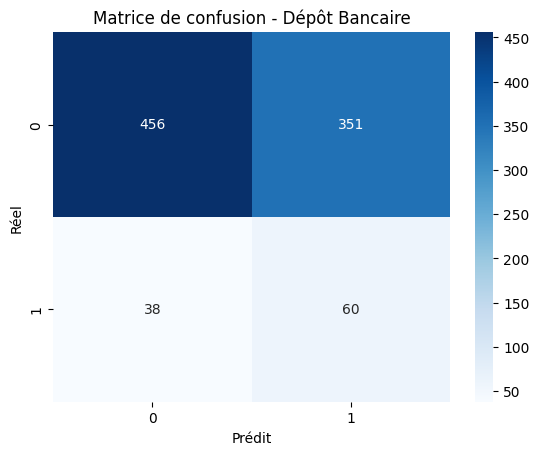

In [55]:
from sklearn.metrics import confusion_matrix 
import seaborn as sns 
import matplotlib.pyplot as plt 
cm1 = confusion_matrix(y_test, y_pred_log) 
sns.heatmap(cm1, annot=True, fmt='d', cmap='Blues') 
plt.title('Matrice de confusion - Dépôt Bancaire') 
plt.xlabel('Prédit') 
plt.ylabel('Réel') 
plt.show() 

### 8. Visualisation : Matrice de confusion (Random Forest)

Cette seconde matrice illustre les prédictions du modèle **Random Forest** (`y_pred_rf`). Contrairement à la Régression Logistique, la matrice confirme visuellement que ce modèle n'a pas réussi à surmonter le déséquilibre des données.

* **Vrais Négatifs (796) :** Clients ayant refusé le dépôt, correctement identifiés en masse.
* **Faux Positifs (11) :** Très peu de fausses alertes sur la classe majoritaire.
* **Faux Négatifs (88) :** L'écrasante majorité des vrais clients intéressés a été ratée.
* **Vrais Positifs (10) :** Seulement 10 clients souscripteurs ont été détectés avec succès.

**Interprétation finale pour le projet :**
Cette visualisation met parfaitement en évidence le "piège de l'Accuracy" évoqué précédemment. Le modèle Random Forest obtient un score global de 89% simplement parce qu'il prédit la classe "0" (non) presque systématiquement. Malgré l'ajout du paramètre `class_weight='balanced'`, la structure complexe des arbres de décision a continué de favoriser la classe majoritaire. 


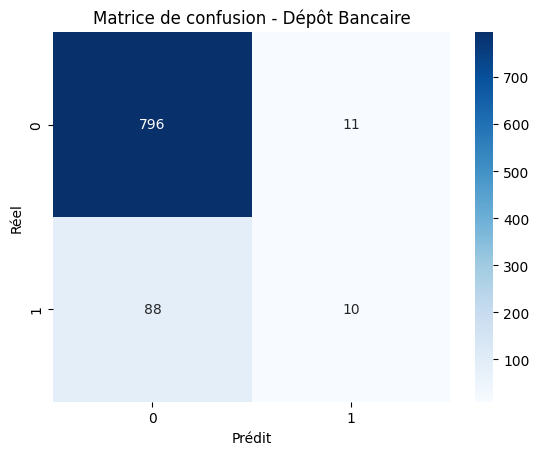

In [57]:
cm2 = confusion_matrix(y_test, y_pred_rf) 
sns.heatmap(cm2, annot=True, fmt='d', cmap='Blues') 
plt.title('Matrice de confusion - Dépôt Bancaire') 
plt.xlabel('Prédit') 
plt.ylabel('Réel') 
plt.show() 

### **Conclusion du mini-projet :** 
Le modèle à retenir pour ce cas d'usage bancaire est définitivement la **Régression Logistique**. Bien que son Accuracy globale soit plus faible, c'est le seul algorithme qui répond au besoin métier : identifier efficacement les clients susceptibles de souscrire un dépôt (maximisation du Recall de la classe 1) pour optimiser les campagnes de démarchage.